In [9]:
# -*- coding: utf-8 -*-
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                           roc_curve, auc, mean_squared_error, r2_score,
                           mean_absolute_error, cohen_kappa_score)
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.tree import plot_tree
import shap

# Установка стилей
plt.style.use('seaborn-v0_8')  # Исправленный стиль
sns.set_theme(style="whitegrid")  # Альтернативный способ установки стиля

# Загрузка данных для красного и белого вина
red_wine = pd.read_csv('wine+quality/winequality-red.csv', sep=';')
white_wine = pd.read_csv('wine+quality/winequality-white.csv', sep=';')


In [12]:

# Добавляем тип вина
red_wine['wine_type'] = 0#'red'
white_wine['wine_type'] = 1#'white'

# Объединяем датасеты
wines = pd.concat([red_wine, white_wine], ignore_index=True)

# ======================
# 1. Анализ и подготовка данных
# ======================
print("1. Анализ данных...")
print(f"Всего образцов: {len(wines)}")
print(f"Красное вино: {len(red_wine)}, Белое вино: {len(white_wine)}")

1. Анализ данных...
Всего образцов: 6497
Красное вино: 1599, Белое вино: 4898


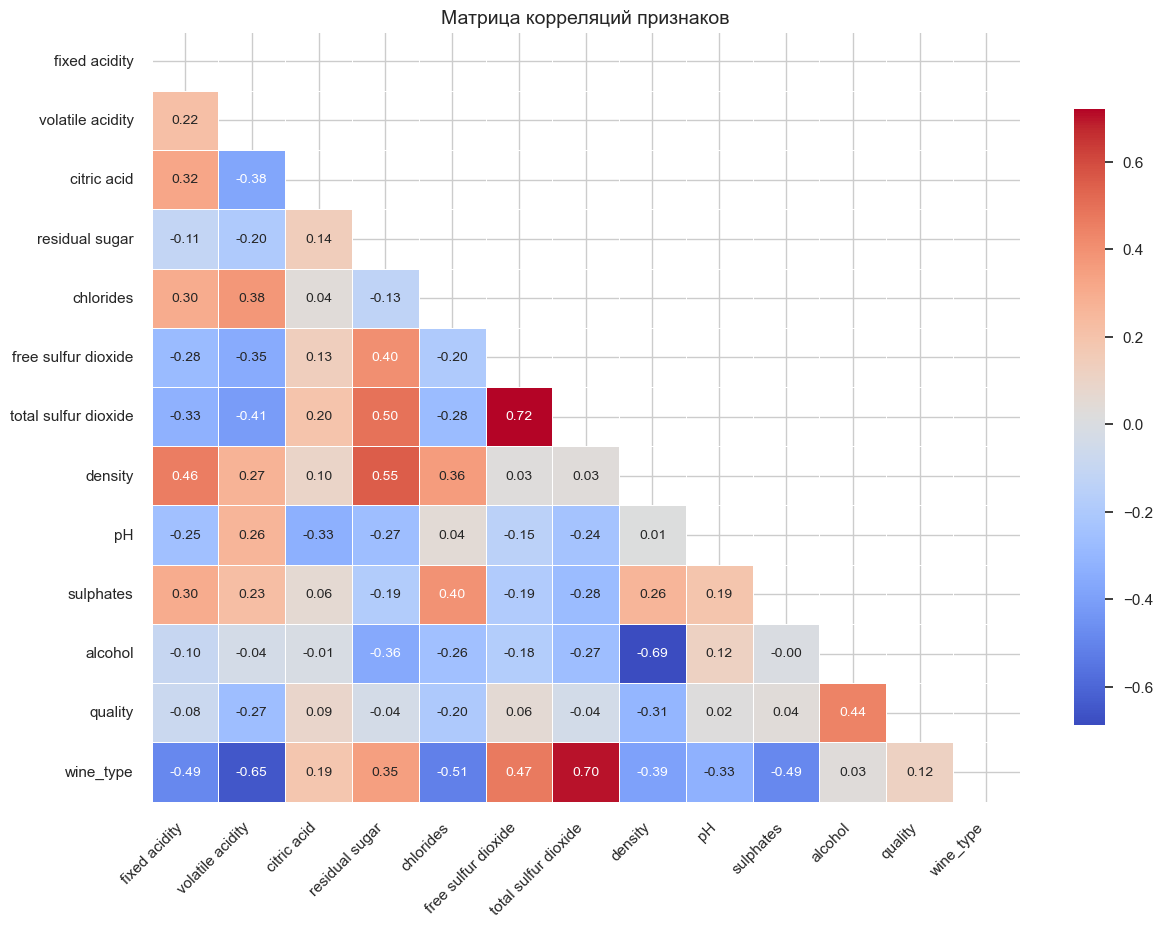

In [13]:

# Корреляционный анализ
plt.figure(figsize=(14, 10))
corr = wines.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm',
           annot_kws={"size": 10}, linewidths=0.5, cbar_kws={"shrink": .8})
plt.title('Матрица корреляций признаков', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.savefig('correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


In [14]:

# ======================
# 2. Многоклассовая классификация
# ======================
print("\n2. Многоклассовая классификация...")

# Подготовка данных
X = wines.drop(['quality', 'quality_class', 'wine_type'], axis=1)
y_class = wines['quality_class']
le = LabelEncoder()
y_encoded = le.fit_transform(y_class)

# Разделение данных
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded)

# Пайплайн с масштабированием
pipeline_clf = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(random_state=42, class_weight='balanced'))
])

# Подбор гиперпараметров
param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [None, 10, 20],
    'clf__min_samples_split': [2, 5, 10]
}

grid_clf = GridSearchCV(pipeline_clf, param_grid, cv=5,
                       scoring='accuracy', n_jobs=-1, verbose=1)
grid_clf.fit(X_train, y_train)



2. Многоклассовая классификация...


KeyError: "['quality_class'] not found in axis"

In [ ]:

# Лучшая модель
best_clf = grid_clf.best_estimator_
print(f"\nЛучшие параметры:\n{grid_clf.best_params_}")

# Оценка модели
y_pred = best_clf.predict(X_test)
y_proba = best_clf.predict_proba(X_test)

print("\nОтчет о классификации:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

print("\nCohen's Kappa:", cohen_kappa_score(y_test, y_pred))


In [ ]:

# Матрица ошибок
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)
plt.title('Матрица ошибок классификации', fontsize=14)
plt.xlabel('Предсказанный класс', fontsize=12)
plt.ylabel('Истинный класс', fontsize=12)
plt.savefig('confusion_matrix_multiclass.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:

# ======================
# 3. Регрессионный анализ
# ======================
print("\n3. Регрессионный анализ...")

y_reg = wines['quality']

# Разделение данных (используем те же разбиения)
X_train_reg, X_test_reg = X_train, X_test
y_train_reg, y_test_reg = y_reg[y_train.index], y_reg[y_test.index]

pipeline_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('reg', RandomForestRegressor(random_state=42))
])

param_grid_reg = {
    'reg__n_estimators': [100, 200],
    'reg__max_depth': [None, 10, 20],
    'reg__min_samples_split': [2, 5, 10]
}

grid_reg = GridSearchCV(pipeline_reg, param_grid_reg, cv=5,
                       scoring='neg_mean_squared_error', n_jobs=-1)
grid_reg.fit(X_train_reg, y_train_reg)

best_reg = grid_reg.best_estimator_
print(f"\nЛучшие параметры регрессии:\n{grid_reg.best_params_}")

In [ ]:


# Оценка модели
y_pred_reg = best_reg.predict(X_test_reg)

print("\nМетрики регрессии:")
print(f"MSE: {mean_squared_error(y_test_reg, y_pred_reg):.3f}")
print(f"MAE: {mean_absolute_error(y_test_reg, y_pred_reg):.3f}")
print(f"R²: {r2_score(y_test_reg, y_pred_reg):.3f}")

# График предсказаний
plt.figure(figsize=(10, 6))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.6, edgecolors='w', linewidth=0.5)
plt.plot([y_test_reg.min(), y_test_reg.max()],
         [y_test_reg.min(), y_test_reg.max()], '--r', linewidth=2)
plt.xlabel('Истинное качество', fontsize=12)
plt.ylabel('Предсказанное качество', fontsize=12)
plt.title('Результаты регрессионной модели', fontsize=14)
plt.grid(True, alpha=0.3)
plt.savefig('regression_results.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:

# ======================
# 4. Анализ важности признаков
# ======================
print("\n4. Анализ важности признаков...")

# Важность признаков (классификация)
importances_clf = best_clf.named_steps['clf'].feature_importances_
indices_clf = np.argsort(importances_clf)[::-1]

plt.figure(figsize=(12, 6))
plt.title("Важность признаков (классификация)", fontsize=14)
plt.bar(range(X.shape[1]), importances_clf[indices_clf], align="center")
plt.xticks(range(X.shape[1]), X.columns[indices_clf], rotation=45, ha="right")
plt.xlim([-1, X.shape[1]])
plt.tight_layout()
plt.savefig('feature_importance_clf.png', dpi=300, bbox_inches='tight')
plt.show()



In [ ]:

# Важность признаков (регрессия)
importances_reg = best_reg.named_steps['reg'].feature_importances_
indices_reg = np.argsort(importances_reg)[::-1]

plt.figure(figsize=(12, 6))
plt.title("Важность признаков (регрессия)", fontsize=14)
plt.bar(range(X.shape[1]), importances_reg[indices_reg], align="center")
plt.xticks(range(X.shape[1]), X.columns[indices_reg], rotation=45, ha="right")
plt.xlim([-1, X.shape[1]])
plt.tight_layout()
plt.savefig('feature_importance_reg.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:

# SHAP-значения для интерпретации
explainer = shap.TreeExplainer(best_clf.named_steps['clf'])
shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(12, 6))
shap.summary_plot(shap_values, X_test, feature_names=X.columns,
                 class_names=le.classes_, plot_type="bar", show=False)
plt.title("SHAP-значения (среднее влияние на выход модели)", fontsize=14)
plt.tight_layout()
plt.savefig('shap_values.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:

# ======================
# 5. Визуализация деревьев
# ======================
print("\n5. Визуализация деревьев...")

# Выбираем несколько деревьев для визуализации
plt.figure(figsize=(20, 10))
plot_tree(best_clf.named_steps['clf'].estimators_[0],
          feature_names=X.columns,
          class_names=le.classes_,
          filled=True, rounded=True,
          max_depth=2, proportion=True,
          fontsize=10)
plt.title("Пример дерева из Random Forest (глубина 2)", fontsize=14)
plt.savefig('decision_tree_sample.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:

# ======================
# 6. Дополнительные исследования
# ======================
# Анализ для разных типов вина
print("\n6. Анализ для разных типов вина...")

for wine_type in ['red', 'white']:
    print(f"\nАнализ для {wine_type} вина:")
    wine_data = wines[wines['wine_type'] == wine_type]
    X_wine = wine_data.drop(['quality', 'quality_class', 'wine_type'], axis=1)
    y_wine = wine_data['quality']
    
    # Регрессия
    reg = RandomForestRegressor(**grid_reg.best_params_['reg__params'])
    scores = cross_val_score(reg, X_wine, y_wine, cv=5, scoring='r2')
    print(f"Средний R² ({wine_type}): {scores.mean():.3f} ± {scores.std():.3f}")
    
    # Важность признаков
    reg.fit(X_wine, y_wine)
    importances = reg.feature_importances_
    top_features = pd.Series(importances, index=X_wine.columns).sort_values(ascending=False)
    print(f"\nТоп-3 признака для {wine_type} вина:")
    print(top_features.head(3))


In [ ]:

# Сохранение результатов
results = {
    'classification_report': classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True),
    'regression_metrics': {
        'mse': mean_squared_error(y_test_reg, y_pred_reg),
        'mae': mean_absolute_error(y_test_reg, y_pred_reg),
        'r2': r2_score(y_test_reg, y_pred_reg)
    },
    'top_features_clf': pd.Series(importances_clf, index=X.columns).sort_values(ascending=False).head(5).to_dict(),
    'top_features_reg': pd.Series(importances_reg, index=X.columns).sort_values(ascending=False).head(5).to_dict()
}

print("\nАнализ завершен. Все графики сохранены в рабочую директорию.")